# CA1 – Machine Learning
## Predicting Maternal Health Risk during Pregnancy

- **Student:** Daniella Silveira e Silva
- **Programme:** HDip in Science in Data Analytics for Business – CCT College Dublin
- **Module:** Machine Learning | **Lecturer:** Dr. Muhammad Iqbal
- **GitHub:** https://github.com/Daniella-CCT/Machine-Learning-Sept26
- **Dataset:** Maternal Health Risk (Ahmed, 2020), UCI Machine Learning Repository – https://archive.ics.uci.edu/dataset/863/maternal+health+risk

This notebook follows the six phases of the **CRISP-DM** methodology (Larose and Larose, 2014): business understanding, data understanding, data preparation, modelling, evaluation and deployment (section 8). All models were built with scikit-learn (Pedregosa et al., 2011).

In [1]:
# ===== Libraries =====
import pandas as pd                 # data handling
import matplotlib.pyplot as plt     # charts
import seaborn as sns               # statistical charts
from scipy import stats             # statistical tests

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")   # hide library warnings to keep the output clean

RANDOM_STATE = 42                   # fixed seed, so the results can be reproduced
sns.set_style("whitegrid")
COLORS = {"low risk": "#4C9F70", "mid risk": "#F2B134", "high risk": "#D1495B"}

## 1. Business understanding

In 2023, about 260,000 women died from complications of pregnancy and childbirth, and most of these deaths were preventable (WHO, 2025). High blood pressure during pregnancy (pre-eclampsia and eclampsia) is one of the main causes. Early identification of high-risk pregnancies helps health workers decide which women need care first, especially in rural areas where women do not see a doctor often.

**Goal:** build classification models that predict the **risk level** of a pregnant woman (low, mid or high) from six vital signs, and find out which signs matter most.

**Questions for this project:**
1. Which features are the most important for predicting the maternal risk level?
2. Which classifier is more suitable for this problem – Random Forest or Support Vector Machine (SVM) – and why?
3. How do the size of the test split and hyperparameter tuning affect accuracy and generalisation?

## 2. Data understanding
### 2.1 Load and describe the dataset

The data was collected from hospitals and community clinics in rural Bangladesh through an IoT-based risk monitoring system (Ahmed et al., 2020). Each row is one pregnant woman.

| Column | Description | Unit |
|---|---|---|
| Age | Age of the woman during pregnancy | years |
| SystolicBP | Upper value of the blood pressure | mmHg |
| DiastolicBP | Lower value of the blood pressure | mmHg |
| BS | Blood sugar (glucose) level | mmol/L |
| BodyTemp | Body temperature | °F |
| HeartRate | Resting heart rate | beats per minute |
| **RiskLevel** | **Target:** risk level during pregnancy | low / mid / high risk |

In [2]:
# Load the dataset (the CSV file must be in the same folder as this notebook)
df = pd.read_csv("maternal_health_risk.csv")

print("Number of rows and columns:", df.shape)
df.head()

Number of rows and columns: (1014, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
# Data types and missing values
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB

Missing values per column:
Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64


In [4]:
# Summary statistics of the six features
df.describe().round(2)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.00,1014.0,1014.00,1014.00,1014.00,1014.00
mean,29.87,113.2,76.46,8.73,98.67,74.30
std,13.47,18.4,13.89,3.29,1.37,8.09
min,10.00,70.0,49.00,6.00,98.00,7.00
25%,19.00,100.0,65.00,6.90,98.00,70.00
50%,26.00,120.0,80.00,7.50,98.00,76.00
75%,39.00,120.0,90.00,8.00,98.00,80.00
max,70.00,160.0,100.00,19.00,103.00,90.00


**Observations**
- There are 1.014 records, 6 numeric features and 1 categorical target. There are **no missing values.**
- Th minimum **HeartRate is 7 bpm**, which is imossible for a living person. This is a recording error.
- **Age** goes from 10 to 70 years. Some of these ages are very unlikely for a pregnancy (see section 3.3).
- **BodyTemp** is 98°F for most women (the 25th, 50th and 75th percentiles are all 98).

### 2.2 Target variable

RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64


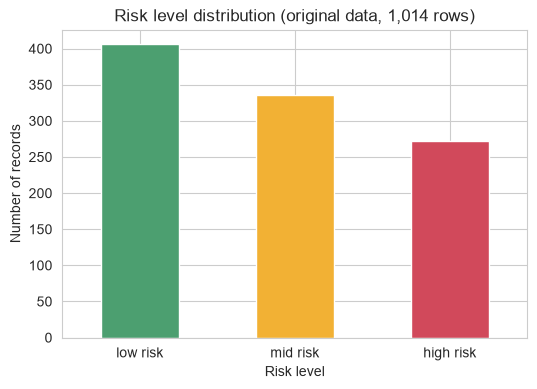

In [5]:
# Distribution of the target variable (risk level)
class_names = ["low risk", "mid risk", "high risk"]
counts = df["RiskLevel"].value_counts()[class_names]
print(counts)

counts.plot(kind="bar", color=[COLORS[c] for c in class_names], figsize=(6, 4))
plt.title(f"Risk level distribution (original data, {len(df):,} rows)")
plt.xlabel("Risk level")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.show()

The classes are not balanced: low risk is the largest group (406 records), followed by mid risk (336) and high risk (272).

### 2.3 Duplicate records

In [6]:
# Count the rows that are exact copies of nother row
n_dup = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dup} of {len(df)} ({n_dup / len(df):.1%})")

Exact duplicate rows: 562 of 1014 (55.4%)


**More than half of the records (55.4%) are exact copies of other records.** If they stay in the data, the same record can appear in both the training set and the test set. The model would then be tested on data it has already seen, and the accuracy would look better than it really is. This problem is called data leakage (Kaufman et al., 2012). Section 3.3 measures this effect.

## 3. Data preparation
### 3.1 Remove impossible values and duplicates

In [7]:
# Step 1: remove records with an impossible heart rate (7 bpm is a recording error)
print("Records with HeartRate below 40 bpm:", (df["HeartRate"] < 40).sum())
df_clean = df[df["HeartRate"] >= 40]

# Step 2: remove exact duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Rows before cleaning:", len(df))
print("Rows after cleaning: ", len(df_clean))
print("\nClass distribution after cleaning:")
print(df_clean["RiskLevel"].value_counts()[class_names])

Records with HeartRate below 40 bpm: 2
Rows before cleaning: 1014
Rows after cleaning:  451

Class distribution after cleaning:
RiskLevel
low risk     233
mid risk     106
high risk    112
Name: count, dtype: int64


After cleaning, **451 records** remain, which is above the minimum of 300 records required for this project. Low risk is now about half of the records (233 of 451).

### 3.2 Features and target
The target is encoded as ordered numbers (low = 0, mid = 1, high = 2). The **majority-class baseline** is the accuracy of a naive model that always predicts "low risk". A useful model must be clearly better than this baseline.

In [8]:
# Features (X) and target (y)
features = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
X = df_clean[features]

# Encode the target as ordered numbers: Low = 0, mid = 1, high = 2
risk_map = {"low risk": 0, "mid risk": 1, "high risk": 2}
y = df_clean["RiskLevel"].map(risk_map)

#Accuracy of a naive model that always predict the ost frequent class (baseline)
baseline = y.value_counts(normalize=True).max()
print("X shape:", X.shape, "| y shape:", y.shape)
print(f"Majority-class baseline accuracy: {baseline:.3f}")

X shape: (451, 6) | y shape: (451,)
Majority-class baseline accuracy: 0.517


### 3.3 Data quality checks
Two quick checks with default models and 5-fold cross-validation:
1. **Duplicates:** how the accuracy changes if the duplicate records are kept.
2. **Implausible ages:** 69 records have an age of 10–12 years or over 50 years, which is very unlikely during pregnancy. This check shows if removing them changes the results.

The SVM uses **StandardScaler**, which the lecture notes recommend for SVM, because SVM is based on distances and is sensitive to the scale of the features. RobustScaler was not used because BodyTemp has an interquartile range of zero (most values are 98 °F). Random Forest does not need scaled features.

In [9]:
# 5-fold stratified cross-validation (keeps the class proportions in every fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Default models, used in the checks below and in section 5
rf_default = RandomForestClassifier(random_state=RANDOM_STATE)
svm_default = make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE))

def cv_accuracy(model, X_data, y_data):
    """Mean accuracy of a model using 5-fold cross-validation."""
    return cross_val_score(model, X_data, y_data, cv=cv, scoring="accuracy").mean()

# Check 1: data WITH the duplicates (only the impossible heart rate removed)
df_dup = df[df["HeartRate"] >= 40]
X_dup, y_dup = df_dup[features], df_dup["RiskLevel"].map(risk_map)

# Check 2: clean data WITHOUT the implausible ages (Age < 13 or Age > 50)
odd_age = (df_clean["Age"] < 13) | (df_clean["Age"] > 50)
print("Records with an implausible age for pregnancy:", odd_age.sum())
X_age, y_age = X[~odd_age], y[~odd_age]

checks = pd.DataFrame({
    "Data version": ["Clean data (used in this project)", "With duplicates", "Without implausible ages"],
    "Rows": [len(X), len(X_dup), len(X_age)],
    "RF accuracy (CV)": [cv_accuracy(rf_default, X, y), cv_accuracy(rf_default, X_dup, y_dup),
                         cv_accuracy(rf_default, X_age, y_age)],
    "SVM accuracy (CV)": [cv_accuracy(svm_default, X, y), cv_accuracy(svm_default, X_dup, y_dup),
                          cv_accuracy(svm_default, X_age, y_age)],
})
checks.round(3)

Records with an implausible age for pregnancy: 69


,Data version,Rows,RF accuracy (CV),SVM accuracy (CV)
0,Clean data (used in this project),451,0.650,0.703
1,With duplicates,1012,0.851,0.698
2,Without implausible ages,382,0.649,0.686


**Results of the checks**
- **With duplicates**, Random Forest reaches an accuracy of 0.851, against 0.650 on the clean data. This higher value is not real: it comes from copies of the same records in the training and validation folds. For this reason, the duplicates were removed.
- **Without the implausible ages**, the accuracy changes very little (Random Forest 0.649 vs 0.650; SVM 0.686 vs 0.703). These records were **kept**, because removing them does not change the conclusions and the dataset gives no information to confirm that they are errors. This is noted as a limitation.

## 4. Feature significance (statistical reasoning)
The boxplots show how each feature changes across the three risk levels.

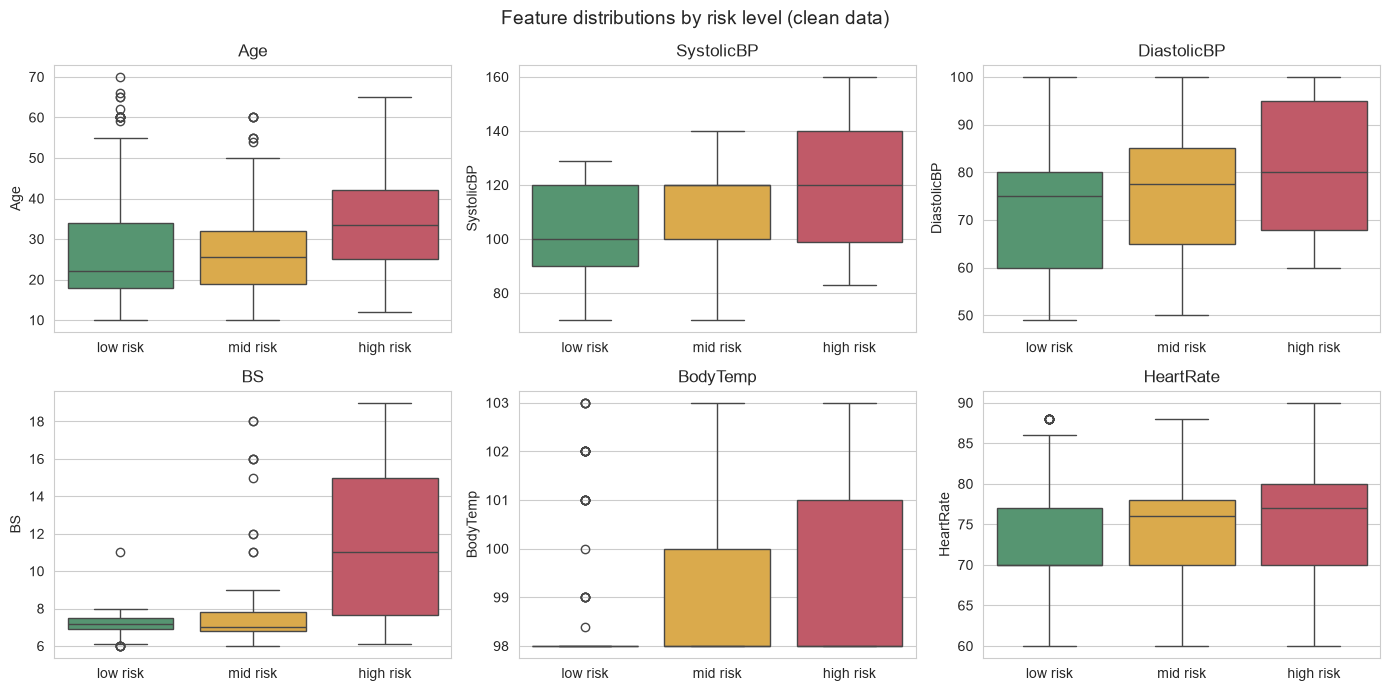

In [10]:
# Boxplots: how each feature changes across the three risk levels
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(data=df_clean, x="RiskLevel", y=col, order=class_names,
                hue="RiskLevel", hue_order=class_names, dodge=False,
                palette=[COLORS[c] for c in class_names], ax=ax)
    if ax.get_legend() is not None:   # the colours already match the x-axis labels
        ax.get_legend().remove()
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Feature distributions by risk level (clean data)", fontsize=14)
plt.tight_layout()
plt.show()

**Observations:** women with **high risk** have clearly higher blood sugar (BS) and higher blood pressure. Low-risk and mid-risk women have similar values in most features, which suggests that these two classes will be harder to separate.

The correlation matrix checks if some features carry the same information.

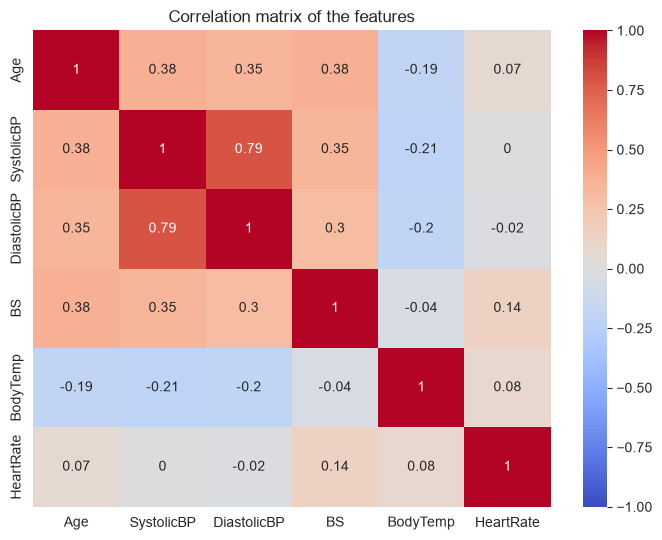

In [11]:
# Correlation between the features (Pearson)
plt.figure(figsize=(7, 5.5))
sns.heatmap(X.corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix of the features")
plt.tight_layout()
plt.show()

Systolic and diastolic blood pressure are strongly correlated (0.79), which is expected. All other correlations are weak or moderate (below 0.4). With only six features and little redundancy, **dimensionality reduction (for example PCA) is not needed** in this project: it would not reduce the complexity in a meaningful way, and it would make the results harder to interpret.

Two statistical tests were used to check if the differences between the risk groups are significant:
- **Kruskal-Wallis H test** (Kruskal and Wallis, 1952): a non-parametric test that compares the three groups without assuming a normal distribution. This is important here because several features are skewed (for example BS and BodyTemp).
- **One-way ANOVA**: compares the group means, as a second check.

Null hypothesis (H0): the feature has the same distribution in the three risk groups. If p < 0.05, H0 is rejected.

In [12]:
# Kruskal-Wallis test (non-parametric) and one-way ANOVA for each feature
# H0: the feature has the same distribution in the three risk groups
rows = []
for col in features:
    groups = [df_clean.loc[df_clean["RiskLevel"] == c, col] for c in class_names]
    h_stat, p_kw = stats.kruskal(*groups)
    f_stat, p_anova = stats.f_oneway(*groups)
    rows.append({"Feature": col, "Kruskal-Wallis H": h_stat, "Kruskal-Wallis p-value": p_kw,
                 "ANOVA F": f_stat, "ANOVA p-value": p_anova})

significance = pd.DataFrame(rows).sort_values("Kruskal-Wallis H", ascending=False)
significance["Significant (p < 0.05)"] = significance["Kruskal-Wallis p-value"] < 0.05
significance.round({"Kruskal-Wallis H": 2, "ANOVA F": 2})

,Feature,Kruskal-Wallis H,Kruskal-Wallis p-value,ANOVA F,ANOVA p-value,Significant (p < 0.05)
3,BS,106.65,6.936817e-24,114.15,8.599894e-41,True
1,SystolicBP,44.78,1.885450e-10,27.15,7.436853e-12,True
4,BodyTemp,31.90,1.183313e-07,16.20,1.609950e-07,True
2,DiastolicBP,25.54,2.849203e-06,16.69,1.021172e-07,True
0,Age,23.16,9.336876e-06,8.53,2.323535e-04,True
5,HeartRate,14.44,7.322151e-04,8.19,3.201951e-04,True
